# Module 04: Snow drought in the Boise Mountains

*The code behind GEOS 212: Water in the West, Boise State University*

In lecture we compared two very different winters in the Boise River basin:

* **Water year 2023**, a big snow year, and
* **Water year 2026**, a *snow drought* year.

Every plot on those slides was made with a few dozen lines of Python, using free public data from two federal agencies. This notebook walks through that code, step by step, so you can see exactly how the figures were made, check our work, and ask your own questions of the data.

**Where are we in the water year?** We are in the *snowpack*: the mountain reservoir that stores winter precipitation and releases it as spring and summer streamflow.

### The question
In WY2026 the Boise Mountains got a fairly normal amount of precipitation, yet the snowpack was far below normal. How can that be? There are two kinds of snow drought:

* **Dry snow drought**: not much precipitation fell at all.
* **Warm snow drought**: precipitation fell, but it was too warm, so it fell as rain or melted early.

We'll use data to decide which kind WY2026 was.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order from top to bottom.

## 1. Setup

First we load the Python *libraries* (toolboxes, in the Module 07 workshop analogy) we need, and define a few helper functions. You don't need to understand every line here yet; the comments explain what each piece does.

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

In [2]:
def water_year(dates):
    """Water year: Oct 1 2025 - Sep 30 2026 is water year 2026."""
    return dates.year + (dates.month >= 10)

def wy_axis_date(dates):
    """Map every date onto one shared 'generic' water year (Oct 2000 - Sep 2001),
    so different years can be drawn on the same x-axis."""
    return pd.to_datetime([pd.Timestamp(2000 if d.month >= 10 else 2001, d.month, min(d.day, 28) if d.month == 2 else d.day)
                           for d in dates])

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

## 2. Getting SNOTEL data

**SNOTEL** (SNOw TELemetry) is a network of about 900 automated weather stations run by the USDA Natural Resources Conservation Service (NRCS) in the mountains of the western US. Each station has a *snow pillow* that weighs the snowpack to measure its **snow water equivalent (SWE)**: the depth of water you'd get if you melted all the snow. Stations also measure precipitation and air temperature.

NRCS has a free tool called the [Report Generator](https://wcc.sc.egov.usda.gov/reportGenerator/) that builds a data table from a web address (URL). Look at the URL inside the function below: you can read the site number, the dates, and the variables we're asking for (`WTEQ` = SWE, `PREC` = precipitation, `TAVG` = average air temperature). Try pasting a URL like this into your web browser!

In [3]:
def get_snotel(site, state, start, end):
    """Daily SNOTEL data from the NRCS Report Generator.

    Returns a table (a pandas DataFrame) indexed by date with columns:
      swe, swe_median   snow water equivalent and its 1991-2020 median (inches)
      precip, precip_median   precipitation accumulated since Oct 1, and its median (inches)
      tavg              daily mean air temperature (deg F)
    """
    url = ("https://wcc.sc.egov.usda.gov/reportGenerator/view_csv/customSingleStationReport/daily/"
           f"{site}:{state}:SNTL%7Cid=%22%22%7Cname/{start},{end}/"
           "WTEQ::value,WTEQ::median_1991,PREC::value,PREC::median_1991,TAVG::value")
    text = fetch_text(url, f"snotel_{site}_{start}_{end}.csv")
    df = pd.read_csv(io.StringIO(text), comment="#", parse_dates=["Date"], index_col="Date")
    df.columns = ["swe", "swe_median", "precip", "precip_median", "tavg"]
    return df

We'll use three SNOTEL stations in the upper Boise River basin:

| Station | Site number | Elevation |
|---|---|---|
| Bogus Basin | 978 | 6,370 ft |
| Mores Creek Summit | 637 | 6,100 ft |
| Atlanta Summit | 306 | 7,580 ft |

Let's download both water years for all three stations. Water year 2023 runs from Oct 1, 2022 to Sep 30, 2023.

In [4]:
SITES = {978: "Bogus Basin", 637: "Mores Creek Summit", 306: "Atlanta Summit"}
YEARS = [2023, 2026]

snotel = {}   # a dictionary: snotel[(site, year)] is one table of daily data
for site in SITES:
    for wy in YEARS:
        snotel[(site, wy)] = get_snotel(site, "ID", f"{wy-1}-10-01", f"{wy}-09-30")

# Peek at the first few rows of one table
snotel[(978, 2026)].head()

Downloaded live data -> snotel_978_2022-10-01_2023-09-30.csv


Downloaded live data -> snotel_978_2025-10-01_2026-09-30.csv


Downloaded live data -> snotel_637_2022-10-01_2023-09-30.csv


Downloaded live data -> snotel_637_2025-10-01_2026-09-30.csv


Downloaded live data -> snotel_306_2022-10-01_2023-09-30.csv


Downloaded live data -> snotel_306_2025-10-01_2026-09-30.csv


,swe,swe_median,precip,precip_median,tavg
Date,,,,,
2025-10-01,0.0,0.0,0.0,0.0,47.5
2025-10-02,0.0,0.0,0.2,0.0,48.0
2025-10-03,0.0,0.0,0.7,0.0,42.3
2025-10-04,0.0,0.0,1.3,0.0,41.5
2025-10-05,0.0,0.0,1.3,0.1,40.3


Each row is one day. Notice `swe` is zero in October: there's no snow yet. The `_median` columns hold the **1991-2020 median** for that day of the year, which is what "normal" means in snow-hydrology speak.

> **Note:** WY2026 data are *provisional*, meaning NRCS hasn't finished quality-checking them, and values may change slightly.

## 3. How did the snowpack and precipitation compare to normal?

Let's plot SWE and accumulated precipitation at Bogus Basin (the ski hill you can see from Boise) for both years, with the median for reference.

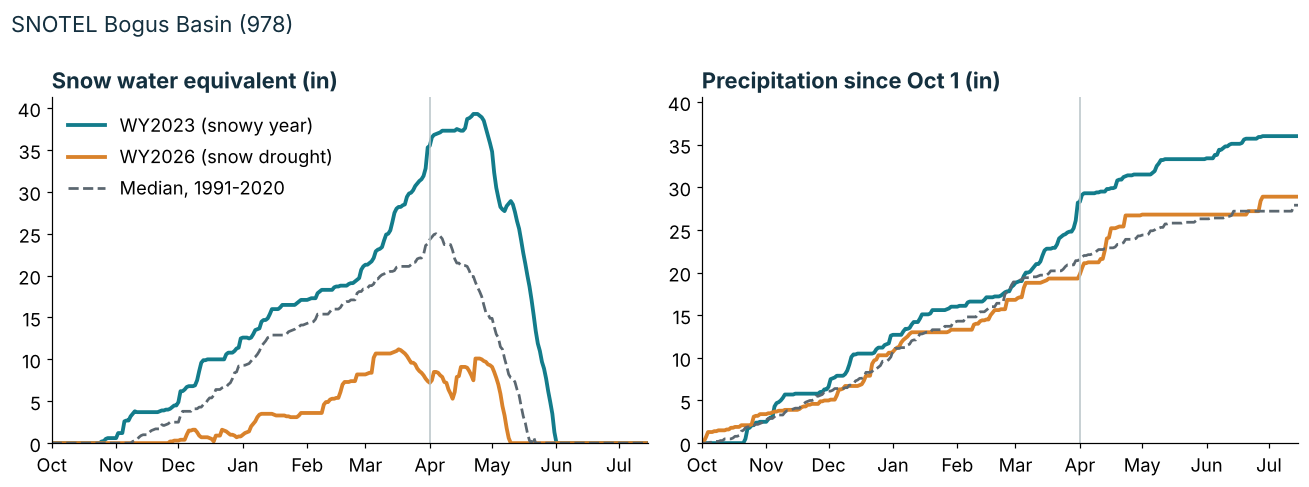

In [5]:
site = 978
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, var, title in [(axs[0], "swe", "Snow water equivalent (in)"),
                       (axs[1], "precip", "Precipitation since Oct 1 (in)")]:
    for wy, color, label in [(2023, RIVER, "WY2023 (snowy year)"), (2026, OCHRE, "WY2026 (snow drought)")]:
        df = snotel[(site, wy)]
        ax.plot(wy_axis_date(df.index), df[var], color=color, lw=2.5, label=label)
    df = snotel[(site, 2023)]
    ax.plot(wy_axis_date(df.index), df[var + "_median"], color=BASALT, ls="--", lw=1.8, label="Median, 1991-2020")
    ax.axvline(pd.Timestamp("2001-04-01"), color="#B8C4C8", lw=1)   # April 1
    month_axis(ax)
    ax.set_xlim(pd.Timestamp("2000-10-01"), pd.Timestamp("2001-07-15"))
    ax.set_ylim(0, None)
    ax.set_title(title, loc="left", fontweight="bold", color=INK)
axs[0].legend(frameon=False, loc="upper left")
fig.suptitle(f"SNOTEL {SITES[site]} ({site})", x=0.01, ha="left", color=INK)
plt.tight_layout()

Hydrologists often summarize a snow year with its **April 1** values, because April 1 is roughly when the snowpack peaks and when water managers make their big decisions about the summer. Let's compute April 1 SWE and precipitation as a percent of median.

In [6]:
# Mores Creek Summit is left out on purpose: it's your job in the "Your turn" section!
rows = []
for (site, wy), df in snotel.items():
    if site == 637:
        continue
    apr1 = df.loc[f"{wy}-04-01"]
    rows.append({"station": SITES[site], "water year": wy,
                 "Apr 1 SWE (in)": apr1.swe,
                 "SWE % of median": round(100 * apr1.swe / apr1.swe_median),
                 "precip % of median": round(100 * apr1.precip / apr1.precip_median)})
apr1_table = pd.DataFrame(rows)
apr1_table

,station,water year,Apr 1 SWE (in),SWE % of median,precip % of median
0,Bogus Basin,2023,35.5,146,131
1,Bogus Basin,2026,7.2,30,92
2,Atlanta Summit,2023,37.4,134,112
3,Atlanta Summit,2026,18.4,66,96


**Look closely at WY2026.** Is precipitation far below normal? Is SWE? If precipitation was close to normal but SWE was way below, where did that water go?

## 4. Rain or snow? Estimating the snow fraction

SNOTEL doesn't record *whether* precipitation fell as rain or snow. But we can estimate it with a simple, widely used rule:

> If the day's mean air temperature was **at or below 1 °C**, assume the precipitation fell as snow. Otherwise, assume rain.

Real precipitation phase depends on humidity and the temperature through the whole atmosphere (remember the melting layer from Module 03), so this is an approximation. But it's a good one to start with.

Steps:
1. Daily precipitation = today's accumulated precipitation minus yesterday's. (The `precip` column is a running total since Oct 1.)
2. Convert temperature from °F to °C.
3. Keep only November through March, the main snow season.
4. Add up the precipitation on "snow days" and divide by the total.

In [7]:
SNOW_THRESHOLD_C = 1.0   # try changing this to 0 or 2 and re-running!

def snow_fraction(df, threshold_c=SNOW_THRESHOLD_C):
    # Accumulated precip is measured at the START of each day, so the precipitation
    # that fell during today = tomorrow's value minus today's value.
    daily_p = (df.precip.shift(-1) - df.precip).clip(lower=0)   # small negative values are sensor noise
    temp_c = (df.tavg - 32) * 5 / 9
    season = df.index.month.isin([11, 12, 1, 2, 3])
    ok = season & daily_p.notna() & temp_c.notna()
    snow = daily_p[ok & (temp_c <= threshold_c)].sum()
    total = daily_p[ok].sum()
    return 100 * snow / total, temp_c[ok].mean(), total

rows = []
for (site, wy), df in snotel.items():
    frac, tmean, ptot = snow_fraction(df)
    rows.append({"station": SITES[site], "water year": wy, "snow %": round(frac),
                 "Nov-Mar mean temp (C)": round(tmean, 1), "Nov-Mar precip (in)": round(ptot, 1)})
snowfrac = pd.DataFrame(rows)
snowfrac

,station,water year,snow %,Nov-Mar mean temp (C),Nov-Mar precip (in)
0,Bogus Basin,2023,97,-4.9,25.8
1,Bogus Basin,2026,53,1.0,16.4
2,Mores Creek Summit,2023,98,-5.4,32.1
3,Mores Creek Summit,2026,70,0.6,23.4
4,Atlanta Summit,2023,99,-6.3,32.2
5,Atlanta Summit,2026,78,-0.3,25.5


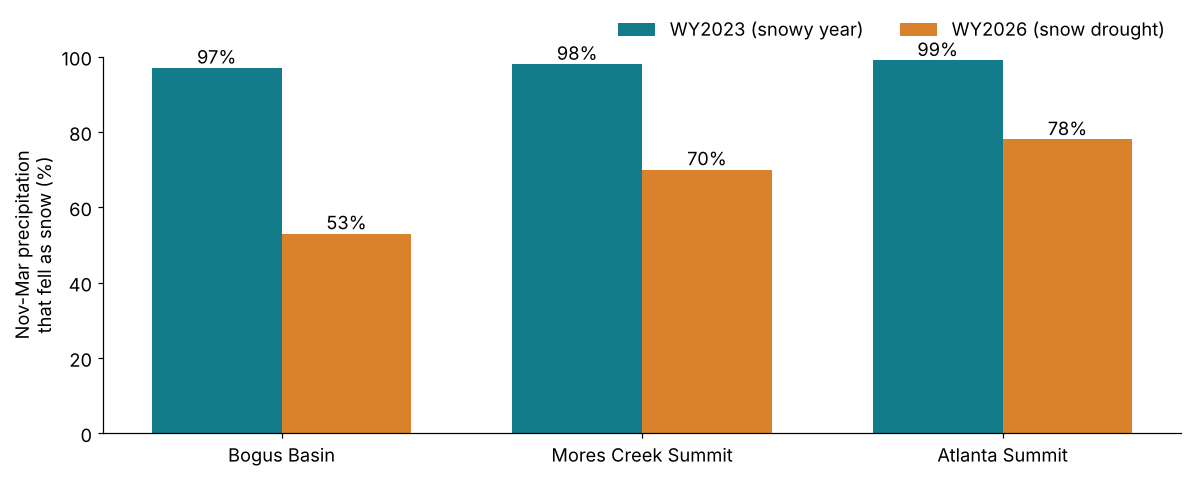

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(SITES)); w = 0.36
for offset, wy, color, label in [(-w/2, 2023, RIVER, "WY2023 (snowy year)"), (w/2, 2026, OCHRE, "WY2026 (snow drought)")]:
    vals = snowfrac[snowfrac["water year"] == wy]["snow %"].values
    bars = ax.bar(x + offset, vals, w, color=color, label=label)
    ax.bar_label(bars, fmt="%d%%")
ax.set_xticks(x, list(SITES.values()))
ax.set_ylim(0, 100)
ax.set_ylabel("Nov-Mar precipitation\nthat fell as snow (%)")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1))
plt.tight_layout()

## 5. Warm or dry? Putting it all on one plot

Here's a neat way to separate the two kinds of snow drought. Plot April 1 **precipitation** (% of median) on the x-axis and April 1 **SWE** (% of median) on the y-axis.

* If a point sits **on the 1:1 line**, the snowpack is about as normal as the precipitation was.
* If a point falls **far below the line**, precipitation fell but didn't stay as snow: a *warm* snow drought.
* If a point is **far to the left**, there just wasn't much precipitation: a *dry* snow drought.

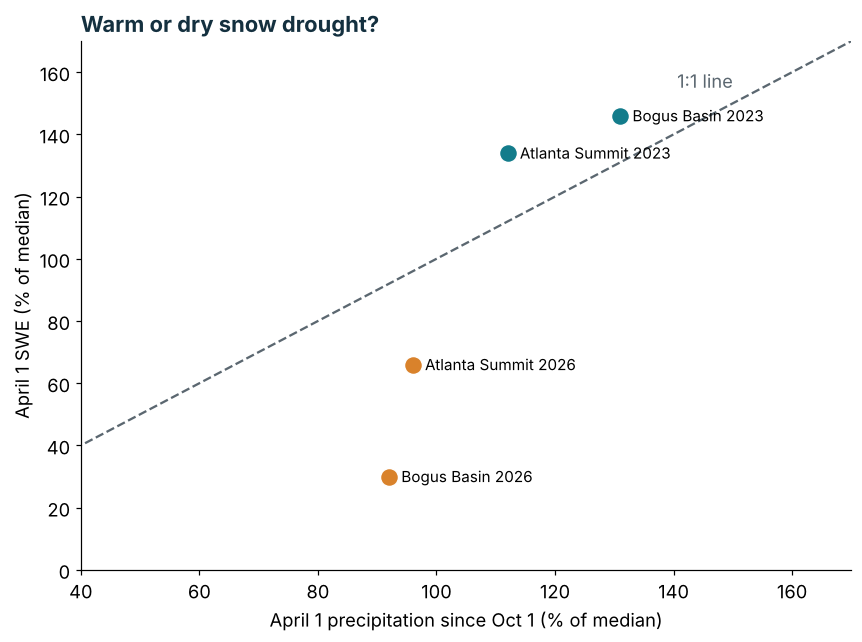

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 170], [0, 170], color=BASALT, ls="--", lw=1.5)
ax.text(150, 155, "1:1 line", color=BASALT, ha="right")
for _, r in apr1_table.iterrows():
    color = RIVER if r["water year"] == 2023 else OCHRE
    ax.scatter(r["precip % of median"], r["SWE % of median"], s=140, color=color, edgecolor="white", zorder=3)
    ax.annotate(f'{r["station"]} {r["water year"]}', (r["precip % of median"], r["SWE % of median"]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=10)
ax.set_xlim(40, 170); ax.set_ylim(0, 170)
ax.set_xlabel("April 1 precipitation since Oct 1 (% of median)")
ax.set_ylabel("April 1 SWE (% of median)")
ax.set_title("Warm or dry snow drought?", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

## 6. What did the river do? Boise River near Twin Springs

Snow matters because it's *storage*: it holds winter precipitation until spring and summer, when farms and cities need water. So what did a warm winter do to the river?

We'll use the US Geological Survey (USGS) stream gage **13185000, Boise River near Twin Springs**. It's upstream of Arrowrock, Anderson Ranch and Lucky Peak reservoirs, so its flow is close to *natural*: what the river does without dams. USGS shares daily flow through its free National Water Information System (NWIS).

In [10]:
def get_usgs_daily_flow(site, start, end):
    """Daily mean discharge (cubic feet per second, cfs) from USGS NWIS.
    Returns a pandas Series indexed by date."""
    url = ("https://waterservices.usgs.gov/nwis/dv/?format=rdb"
           f"&sites={site}&parameterCd=00060&statCd=00003&startDT={start}&endDT={end}")
    text = fetch_text(url, f"usgs_{site}_{start}_{end}.rdb")
    # USGS "rdb" files are tab-separated, with '#' comment lines and a
    # second header row that describes column widths (we skip it).
    df = pd.read_csv(io.StringIO(text), sep="\t", comment="#", dtype=str).iloc[1:]
    flow_col = [c for c in df.columns if c.endswith("_00060_00003")][0]
    q = pd.to_numeric(df[flow_col], errors="coerce")   # turns codes like 'Ice' into NaN
    q.index = pd.to_datetime(df["datetime"])
    return q.dropna().rename("Q_cfs")

In [11]:
q = get_usgs_daily_flow("13185000", "1990-10-01", "2026-09-30")
q.tail()

Downloaded live data -> usgs_13185000_1990-10-01_2026-09-30.rdb


datetime
2026-09-26    304
2026-09-27    308
2026-09-28    309
2026-09-29    306
2026-09-30    305
Name: Q_cfs, dtype: int64

First, the daily hydrograph: each water year's flow, day by day, against the 1991-2020 median for each day of the year.

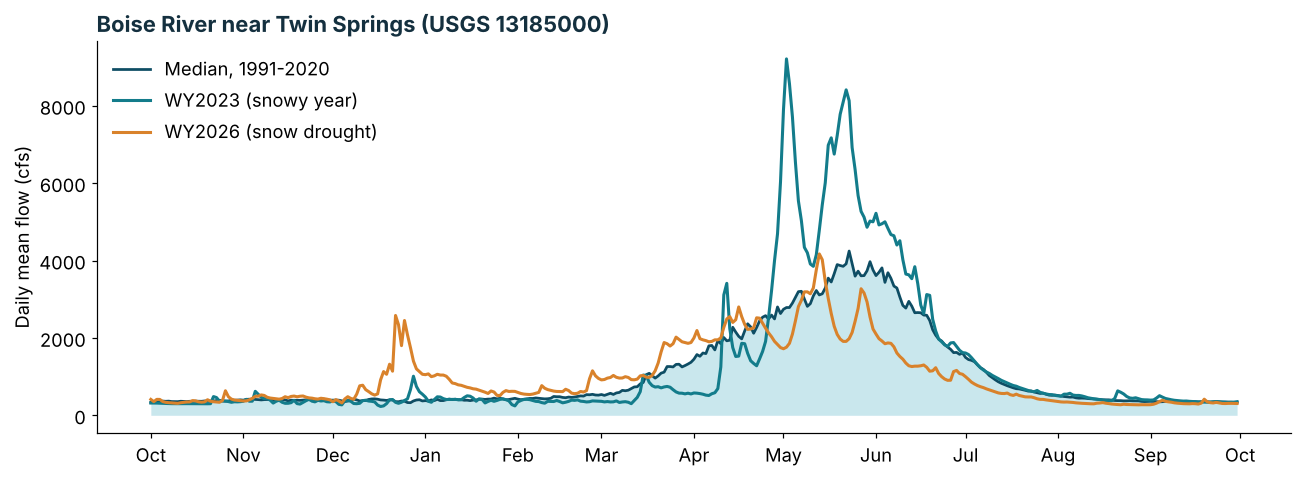

In [12]:
qq = q[~((q.index.month == 2) & (q.index.day == 29))]   # drop leap days so every year has 365 days
daily = pd.DataFrame({"Q": qq.values, "wy": water_year(qq.index), "day": wy_axis_date(qq.index)})
median_day = daily[daily.wy.between(1991, 2020)].groupby("day").Q.median()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(median_day.index, median_day, color=GLACIER, alpha=0.3, lw=0)
ax.plot(median_day.index, median_day, color=DEEP, lw=1.8, label="Median, 1991-2020")
for wy, color, label in [(2023, RIVER, "WY2023 (snowy year)"), (2026, OCHRE, "WY2026 (snow drought)")]:
    d = daily[daily.wy == wy]
    ax.plot(d.day, d.Q, color=color, lw=2, label=label)
month_axis(ax)
ax.set_ylabel("Daily mean flow (cfs)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Boise River near Twin Springs (USGS 13185000)", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

Flow is in **cubic feet per second (cfs)**. To talk about *volumes* of water, western water managers use **acre-feet** (AF): enough water to cover one acre one foot deep, about 326,000 gallons.

One cfs flowing for one full day is:

$$1\ \tfrac{\text{ft}^3}{\text{s}} \times 86{,}400\ \tfrac{\text{s}}{\text{day}} = 86{,}400\ \text{ft}^3 \div 43{,}560\ \tfrac{\text{ft}^3}{\text{acre-ft}} = 1.9835\ \text{acre-feet}$$

So adding up daily cfs values and multiplying by 1.9835 gives a volume in acre-feet.

In [13]:
CFS_DAY_TO_AF = 86400 / 43560   # = 1.9835

flow = q.to_frame()
flow["wy"] = water_year(flow.index)
flow["month"] = flow.index.month

# Monthly volume in thousand acre-feet (KAF) for every water year
monthly = flow.groupby(["wy", "month"]).Q_cfs.sum() * CFS_DAY_TO_AF / 1000
monthly = monthly.unstack("month")            # rows = water years, columns = months
order = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
monthly = monthly[order]
median = monthly.loc[1991:2020].median()
monthly.loc[[2023, 2026]].round(0)

month,10,11,12,1,2,3,4,5,6,7,8,9
wy,,,,,,,,,,,,
2023,20.0,23.0,25.0,25.0,20.0,35.0,109.0,381.0,194.0,55.0,29.0,22.0
2026,23.0,27.0,63.0,47.0,37.0,80.0,130.0,165.0,81.0,36.0,19.0,19.0


Dec-Mar 2026: 227 KAF (1.5 x the median)
May-Jun 2026: 246 KAF (59% of the median)


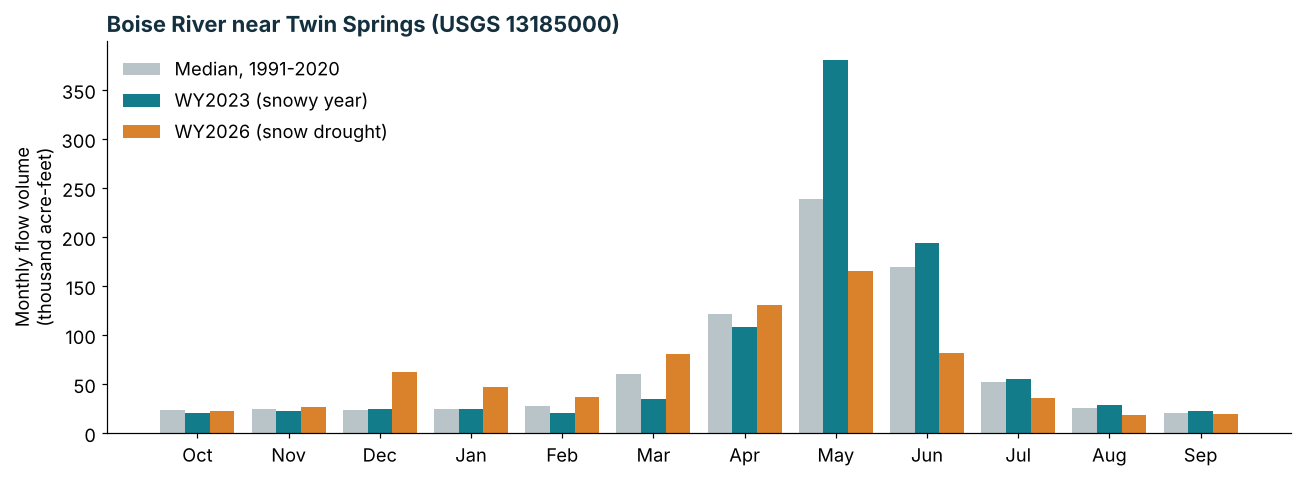

In [14]:
names = ["Oct","Nov","Dec","Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep"]
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(12); w = 0.27
ax.bar(x - w, median, w, color="#B8C4C8", label="Median, 1991-2020")
ax.bar(x,     monthly.loc[2023], w, color=RIVER, label="WY2023 (snowy year)")
ax.bar(x + w, monthly.loc[2026], w, color=OCHRE, label="WY2026 (snow drought)")
ax.set_xticks(x, names)
ax.set_ylabel("Monthly flow volume\n(thousand acre-feet)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Boise River near Twin Springs (USGS 13185000)", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

winter = [12, 1, 2, 3]; spring = [5, 6]
print(f"Dec-Mar 2026: {monthly.loc[2026, winter].sum():.0f} KAF "
      f"({monthly.loc[2026, winter].sum() / monthly.loc[1991:2020, winter].sum(axis=1).median():.1f} x the median)")
print(f"May-Jun 2026: {monthly.loc[2026, spring].sum():.0f} KAF "
      f"({100 * monthly.loc[2026, spring].sum() / monthly.loc[1991:2020, spring].sum(axis=1).median():.0f}% of the median)")

**Read the plot.** In a warm snow drought, water that "should" have been stored as snow ran off in winter instead. What does that mean for reservoirs, irrigators, and the river in late summer?

Finally, how much of a typical year's flow arrives during the April-July snowmelt season?

In [15]:
annual = monthly.sum(axis=1)
apr_jul = monthly[[4, 5, 6, 7]].sum(axis=1)
frac = (apr_jul / annual).loc[1991:2020]
print(f"In a median year, April-July carries {100 * frac.median():.0f}% of the year's flow at Twin Springs.")
print(f"In WY2026 it carried {100 * apr_jul[2026] / annual[2026]:.0f}%.")

In a median year, April-July carries 70% of the year's flow at Twin Springs.
In WY2026 it carried 57%.


## 7. Your turn

Pick one or two of these. Each needs only small changes to code you've already run.

1. **Change the snow threshold.** Set `SNOW_THRESHOLD_C` to 0 °C or 2 °C and re-run section 4. How sensitive are the results to this assumption? Does the conclusion change?
2. **Add a year.** Add another water year to `YEARS` (WY2015 was a famous warm snow drought across the West; WY2017 was a huge snow year). Where does it fall on the warm-vs-dry plot?
3. **Place Mores Creek Summit.** We left station 637 out of the April 1 table and the warm-vs-dry plot. Predict where its two points will land, then remove the `if site == 637: continue` lines and re-run. Were you right?
4. **Add a station.** Find another Idaho SNOTEL site on the [NRCS interactive map](https://nwcc-apps.sc.egov.usda.gov/imap/) and add it to `SITES`. Do higher stations behave differently from lower ones?
5. **Think like a water manager.** Using the monthly flow table, how much *more* water left the basin in Dec-Mar 2026 than in a median winter? The Boise reservoirs together hold about 950,000 acre-feet. Why can't they simply catch all of that early runoff and save it for summer? (Hint: look up *flood control rule curves*.)

### Why code?
You could make these plots in a spreadsheet. But with code, re-running the whole analysis for a new year, station, or assumption takes seconds, every step is written down so someone else can check it, and the same few lines work for any of the ~900 SNOTEL stations and ~10,000 USGS stream gages. That's how much of modern hydrologic science is done.

---
*Data: USDA NRCS SNOTEL (Report Generator) and USGS NWIS. WY2026 data are provisional.*